# Dealer-like liquidity providers and temporary liquidity shocks

**Research question (proposal):** do dealer-like liquidity providers absorb temporary liquidity shocks, and does
their provision help prices and liquidity stabilise?

Mechanism tested: *liquidity shock → liquidity provision → shock absorption → price & liquidity stabilisation.*

| | Data | Role |
|---|---|---|
| Main | **FI-2010** (Ntakaris et al. 2018): 5 Helsinki stocks × 10 days, 10-level book, one snapshot per 10 events | H1–H3, H4 proxy |
| Extension | **LOBSTER** free samples: AAPL, AMZN, GOOG, INTC, MSFT, 21 Jun 2012, 10 levels + message file | H1–H3 with true market-order flow; H4 proper |

Run `bash scripts/download_data.sh` once to fetch the raw data into `data/raw/`. All code lives in `src/mm/`.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Image
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

from mm import analysis as A
from mm.config import FI_TICK, LOB_TICK, FIGS, TABLES
from mm.fi2010 import build_fi2010_book, read_raw_book, surviving_pairs
from mm.config import RAW_FI
from mm.lobster import build_lobster_panel, build_trades
from mm.measures import add_measures, summary_by_stock

## 1. Data preparation

### 1.1 FI-2010 must be split into stock-days
A FI-2010 file is not one time series. Each test file stacks the five stocks of one day; the training file
(days 1–7) stacks stock 1 days 1–7, then stock 2 days 1–7, etc. Event windows that cross these joins compare
two different stocks (this contaminated the earlier notebook).

**Detection rule.** Overnight the whole book is rebuilt, so *no* (side, price, size) pair survives from one
snapshot to the next. Within a day only 10 events separate snapshots, so most of the 20 visible pairs survive.

In [2]:
B = read_raw_book(RAW_FI / "Train_Dst_NoAuction_DecPre_CF_7.txt")
surv = surviving_pairs(B)
print("Snapshots in training file:", len(B))
print("Histogram of surviving (price,size) pairs between consecutive snapshots (0..20):")
print(np.bincount(surv, minlength=21))
print("Steps with <=2 surviving pairs:", int((surv <= 2).sum()), "= 5 stocks x 7 days - 1 =", 5*7-1)
del B

Snapshots in training file: 254750
Histogram of surviving (price,size) pairs between consecutive snapshots (0..20):
[   32     1     1     0     0     3    11    23    83   403  1493  4734
 11186 22085 34458 42969 43577 36554 28185 12478 16473]
Steps with <=2 surviving pairs: 34 = 5 stocks x 7 days - 1 = 34


Exactly 34 breaks in the training file, and none of the in-day steps has fewer than 5 surviving pairs, so the
split is exact. The test files give 4 breaks each. Result: **50 clean stock-day segments**. Price levels confirm
the stock order of Table 1 in Ntakaris et al. (KESBV ≈ €27, OUT1V ≈ €13, SAMPO ≈ €17, RTRKS ≈ €13, WRT1V ≈ €35).
DecPre scaling is uniform: price × 100 = EUR (tick €0.01), size × 10⁵ = shares.

In [3]:
fi = add_measures(build_fi2010_book(), FI_TICK)
lob = add_measures(build_lobster_panel(), LOB_TICK)
trades = build_trades()
display(fi.groupby(["stock", "day"]).size().unstack())

day,1,2,3,4,5,6,7,8,9,10
stock,,,,,,,,,,
KESBV,3454,5079,3903,2806,3030,2263,2801,2647,1873,1888
OUT1V,6318,6122,5411,6992,6728,6243,7060,8662,9271,5128
RTRKS,10719,6712,5186,10819,6378,7007,7854,13229,12880,5821
SAMPO,4922,5965,4027,5342,5946,5607,6740,8591,10036,5722
WRT1V,14099,14519,10008,11064,12703,18032,12891,22349,18112,13378


### 1.2 Measures (proposal §6.1 plus order flow)
* mid-price $M_t$, spread $S_t$, relative spread $RS_t$ (bps), spread in ticks
* depth over 1, 3 and 10 levels per side; depth imbalance $(D^{bid}-D^{ask})/(D^{bid}+D^{ask})$
* **order-flow imbalance (OFI)** of Cont, Kukanov & Stoikov (2014) at the best quotes, and over 3 levels (Xu et al. 2019).
  Depth imbalance is a *stock* of resting orders; OFI is the *flow* (net buying pressure) that the proposal's
  "order-flow imbalance" refers to. OFI is scaled by the stock-day's average best-level depth.
* LOBSTER only: market buy / sell volume and limit-order additions and cancellations near the top of each side,
  taken from the message file.

In [4]:
s1 = summary_by_stock(fi); s2 = summary_by_stock(lob, extra=("buy_vol", "sell_vol"))
display(s1.round(3)); display(s2.round(3))

,snapshots,segments,mid,spread_ticks,rel_spread_bps,dbid1,dask1,dbid10,dask10,imb1,imb10,ofi1n,rvol20
stock,,,,,,,,,,,,,
KESBV,29744,10,26.8300,5.9840,22.3230,397.9040,407.9730,"4,961.6120","5,058.8510",0.0080,-0.0050,-0.0010,2.6210
OUT1V,67935,10,12.8390,2.0640,16.1010,"1,731.3890","1,724.9690","32,249.2500","30,832.4480",-0.0040,0.0190,0.0020,2.3670
RTRKS,86605,10,12.7420,2.2980,18.0540,"1,824.5110","1,639.8450","29,273.5040","30,217.1770",0.0320,-0.0070,0.0030,1.8530
SAMPO,62898,10,17.4470,2.1050,12.0760,"1,877.1720","2,073.1740","32,710.5940","34,356.9880",-0.0120,-0.0260,0.0020,1.8190
WRT1V,147155,10,35.4940,5.6530,15.9690,395.5120,487.5440,"5,367.0730","5,886.6730",-0.0560,-0.0430,0.0010,1.1300


,snapshots,segments,mid,spread_ticks,rel_spread_bps,dbid1,dask1,dbid10,dask10,imb1,imb10,ofi1n,rvol20,buy_vol,sell_vol
stock,,,,,,,,,,,,,,,
AAPL,35142,1,583.4410,15.4520,2.6470,181.4300,136.7340,"1,774.7190","1,435.0840",0.0720,0.0790,-0.0400,0.3820,30.1080,35.0320
AMZN,24343,1,222.8270,13.0690,5.8640,247.2300,131.0990,"1,858.9090","1,433.3370",0.1020,0.0930,0.0030,0.6300,12.9420,13.7940
GOOG,13118,1,570.8810,28.6840,5.0210,159.8140,123.4430,"1,239.3320",904.7980,0.0030,0.1290,-0.0570,0.6490,20.5910,20.2650
INTC,52230,1,27.0470,1.2100,4.4740,"15,456.1870","13,455.7520","151,740.5370","135,647.7680",0.0430,0.0550,-0.0030,0.2560,66.7160,84.8660
MSFT,57484,1,30.5560,1.2200,3.9940,"13,605.7990","14,076.0670","146,103.6150","148,740.0780",-0.0280,-0.0120,-0.0040,0.2860,70.2850,71.9890


## 2. Design

**Shock (H1).** Sum OFI over the last W = 5 steps (50 events). A *sell shock* is a value in that stock's bottom
1%, a *buy shock* one in its top 1%. Events at least 100 steps apart, and every window stays inside one stock-day.
Time 0 = end of the shock window. All paths are **sign-adjusted** so buy and sell shocks can be pooled
(positive price move = move in the shock's direction; "hit side" = bid for a sell shock).

**Matched controls.** Book variables mean-revert by themselves, so a raw before/after comparison overstates
everything. Each event gets 5 control moments from the same stock-day with normal order flow:
* *pre-matched*: same book state just before the shock window (τ = −W) → "what would have happened anyway";
* *state-matched*: same depleted book at τ = 0 but reached without a flow shock → separates a real response to
  the shock from mechanical refilling of a thin book.

Effects are differences-in-differences (event change minus control change).

**Windows.** Provision is measured over (0, 10] steps and recovery over (10, 100], so the two never overlap.

**Inference.** Standard errors are clustered by stock-day (FI-2010) or by stock × 30-minute block (LOBSTER), and
p-values are Holm-adjusted within each hypothesis table.

In [5]:
out = {}
for name, df, cl in (("FI-2010", fi, "seg"), ("LOBSTER", lob, "block")):
    res = A.run_event_study(df, flow_col="ofi1n", W=5, q=0.01, min_gap=100)
    e = A.event_level(res, cluster=cl)
    out[name] = (df, res, e)
    print(f"{name}: {len(e)} shocks ({(e.s==-1).sum()} sell, {(e.s==1).sum()} buy) in {e.cluster.nunique()} clusters")

FI-2010: 1269 shocks (616 sell, 653 buy) in 50 clusters


LOBSTER: 657 shocks (307 sell, 350 buy) in 60 clusters


## 3. Event studies

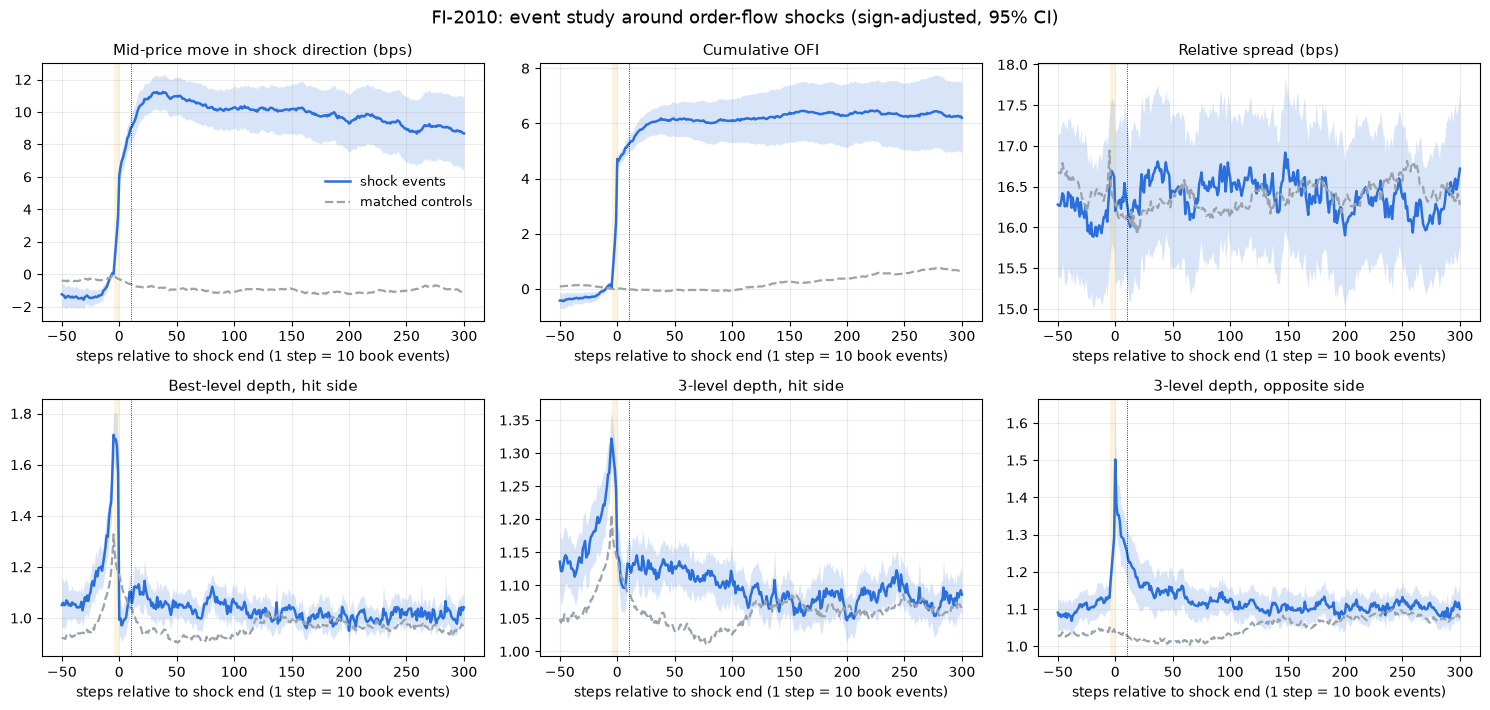

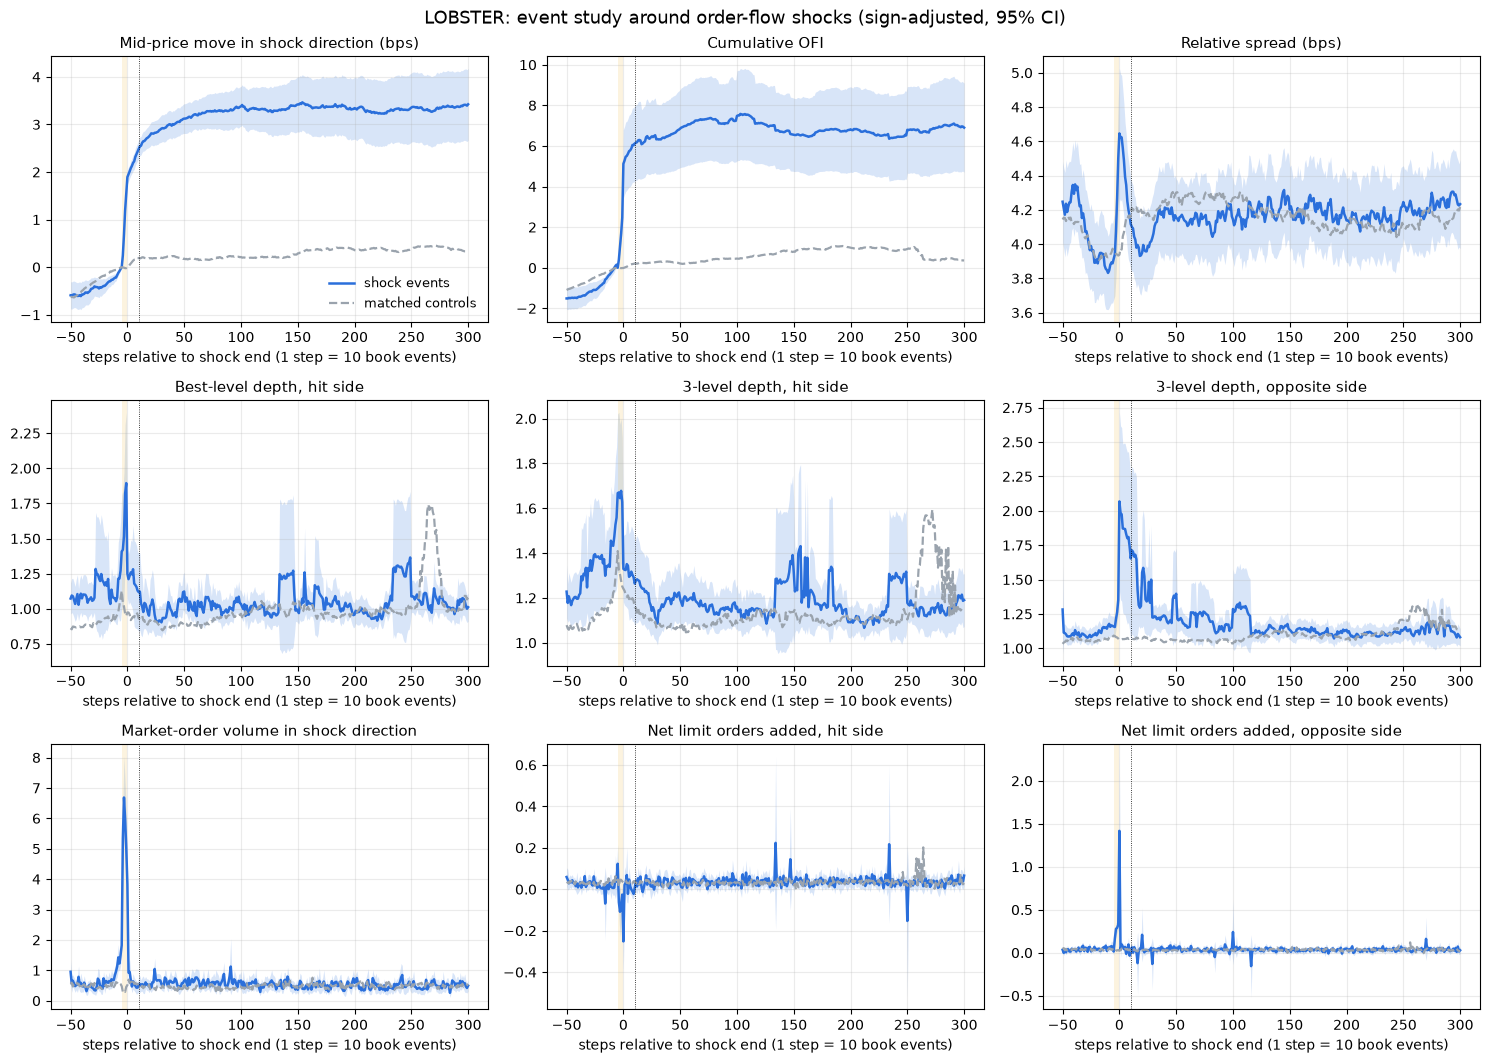

In [6]:
EV = [("mid_bps", "Mid-price move in shock direction (bps)"), ("cofi", "Cumulative OFI"),
      ("rel_spread_bps", "Relative spread (bps)"), ("dep1_press", "Best-level depth, hit side"),
      ("dep_press", "3-level depth, hit side"), ("dep_opp", "3-level depth, opposite side")]
LOBX = [("mo_press", "Market-order volume in shock direction"), ("net_add_press", "Net limit orders added, hit side"),
        ("net_add_opp", "Net limit orders added, opposite side")]
fig = A.plot_event_study(out["FI-2010"][1], "FI-2010", EV, W=5, cluster="seg"); plt.show()
fig = A.plot_event_study(out["LOBSTER"][1], "LOBSTER", EV + LOBX, W=5, cluster="block"); plt.show()

## 4. Hypothesis tests

In [7]:
for name in out:
    df, res, e = out[name]
    display(A.hypothesis_table(e, res, name).drop(columns=["dataset"]).round(4))

,hypothesis,measure,mean,se,t,p,n,clusters,expected,p_holm,sig
0,H1,"Δ relative spread (bps), shock vs control",0.3930,0.2613,1.5043,0.1389,1269,50,> 0,0.5557,
1,H1,"Δ depth on hit side, 3 lvls (× median)",-0.1102,0.0265,-4.1513,0.0001,1269,50,< 0,0.0011,***
2,H1,"Δ depth on hit side, best level (× mean)",-0.5641,0.0458,-12.3159,0.0000,1269,50,< 0,0.0000,***
3,H1,"Δ depth on hit side, 10 lvls (× median)",0.0025,0.0098,0.2549,0.7999,1269,50,< 0,0.7999,
4,H1,Δ book imbalance toward pressure,0.1509,0.0179,8.4201,0.0000,1269,50,> 0,0.0000,***
5,H2,"Contrarian order flow (0,K1] vs same-state con...",-0.5551,0.1558,-3.5618,0.0008,1269,50,> 0,0.0058,***
6,H2,"Hit-side refill (0,K1] vs same-state control",0.0216,0.0175,1.2337,0.2232,1269,50,> 0,0.5557,
7,H2,"Hit-side quote improvements (0,K1] vs control ...",-0.0712,0.0346,-2.0607,0.0447,1269,50,> 0,0.2233,
8,H3/H4,"Price drift after shock (0,K2] vs control, bps",4.9925,0.8176,6.1062,0.0000,1269,50,< 0 if prices revert,0.0000,***
9,H3/H4,"Price drift after shock (0,300] vs control, bps",3.3609,1.2070,2.7845,0.0076,1269,50,< 0 if prices revert,0.0456,**


,hypothesis,measure,mean,se,t,p,n,clusters,expected,p_holm,sig
0,H1,"Δ relative spread (bps), shock vs control",0.7537,0.1588,4.7465,0.0000,657,60,> 0,0.0001,***
1,H1,"Δ depth on hit side, 3 lvls (× median)",-0.1694,0.0821,-2.0647,0.0434,657,60,< 0,0.2168,
2,H1,"Δ depth on hit side, best level (× mean)",-0.0048,0.1167,-0.0415,0.9670,657,60,< 0,1.0000,
3,H1,"Δ depth on hit side, 10 lvls (× median)",-0.0811,0.0267,-3.0359,0.0036,657,60,< 0,0.0250,**
4,H1,Δ book imbalance toward pressure,0.1236,0.0254,4.8743,0.0000,657,60,> 0,0.0001,***
5,H2,"Contrarian order flow (0,K1] vs same-state con...",-0.9995,0.2259,-4.4252,0.0000,657,60,> 0,0.0004,***
6,H2,"Hit-side refill (0,K1] vs same-state control",0.0469,0.0602,0.7789,0.4392,657,60,> 0,1.0000,
7,H2,"Hit-side quote improvements (0,K1] vs control ...",-0.2085,0.0671,-3.1092,0.0029,657,60,> 0,0.0231,**
8,H2,"Net limit orders added on hit side (0,K1] vs c...",-0.1471,0.0840,-1.7515,0.0850,657,60,> 0,0.3402,
9,H3/H4,"Price drift after shock (0,K2] vs control, bps",1.2613,0.2214,5.6958,0.0000,657,60,< 0 if prices revert,0.0000,***


## 5. H3: does stronger provision bring faster stabilisation?

Regression from proposal §7, per event:
$Recovery_i = \beta_0 + \beta_1 LP_i + \gamma' controls_i + FE + \varepsilon_i$.

Controls: log shock size, pre-shock volatility, spread and depth, time of day, and a buy-shock dummy.
Fixed effects: stock-day (FI-2010) or stock (LOBSTER).

LP is standardised, so β₁ is the effect of a 1-SD stronger provision. Three LP measures:
* `lp_flow`: contrarian OFI in (0, K1];
* `lp_refill`: refill of the hit side;
* `lp_msg`: net limit orders added on the hit side (LOBSTER only).

Recovery outcomes, all measured after K1 (except `t_recover`):
* `reversal_bps`: price reversal over (K1, K2];
* `spread_gap_K2` and `depth_gap_K2`: distance from pre-shock levels at K2;
* `t_recover`: steps until both spread and depth are back to normal. It overlaps with LP, so treat it as descriptive.

FI-2010


,LP,outcome,beta_per_sd,se,t,p,n,r2,sig
0,lp_flow,reversal_bps,0.5345,1.2590,0.4245,0.6712,1269,0.0599,
1,lp_flow,spread_gap_K2,0.2128,0.2821,0.7542,0.4507,1269,0.3524,
2,lp_flow,depth_gap_K2,0.0191,0.0273,0.7000,0.4839,1269,0.1723,
3,lp_flow,t_recover,-4.1497,3.3080,-1.2545,0.2097,1269,0.1873,
4,lp_refill,reversal_bps,1.0638,0.6039,1.7615,0.0781,1269,0.0616,*
5,lp_refill,spread_gap_K2,-0.0669,0.2411,-0.2777,0.7813,1269,0.3521,
6,lp_refill,depth_gap_K2,0.0078,0.0160,0.4881,0.6255,1269,0.1718,
7,lp_refill,t_recover,-1.8549,2.5718,-0.7212,0.4708,1269,0.1860,


LOBSTER


,LP,outcome,beta_per_sd,se,t,p,n,r2,sig
0,lp_flow,reversal_bps,-0.0244,0.2011,-0.1213,0.9034,657,0.0661,
1,lp_flow,spread_gap_K2,0.0911,0.0484,1.8823,0.0598,657,0.1506,*
2,lp_flow,depth_gap_K2,-0.0234,0.1343,-0.1744,0.8615,657,0.6031,
3,lp_flow,t_recover,-1.5520,2.6525,-0.5851,0.5585,657,0.1389,
4,lp_refill,reversal_bps,-0.4206,0.1810,-2.3241,0.0201,657,0.0713,**
5,lp_refill,spread_gap_K2,-0.1453,0.0642,-2.2629,0.0236,657,0.1536,**
6,lp_refill,depth_gap_K2,0.0130,0.1620,0.0803,0.9360,657,0.6030,
7,lp_refill,t_recover,-7.8038,4.4003,-1.7735,0.0762,657,0.1432,*
8,lp_msg,reversal_bps,-0.2991,0.3141,-0.9524,0.3409,657,0.0677,
9,lp_msg,spread_gap_K2,-0.0086,0.0820,-0.1043,0.9169,657,0.1479,


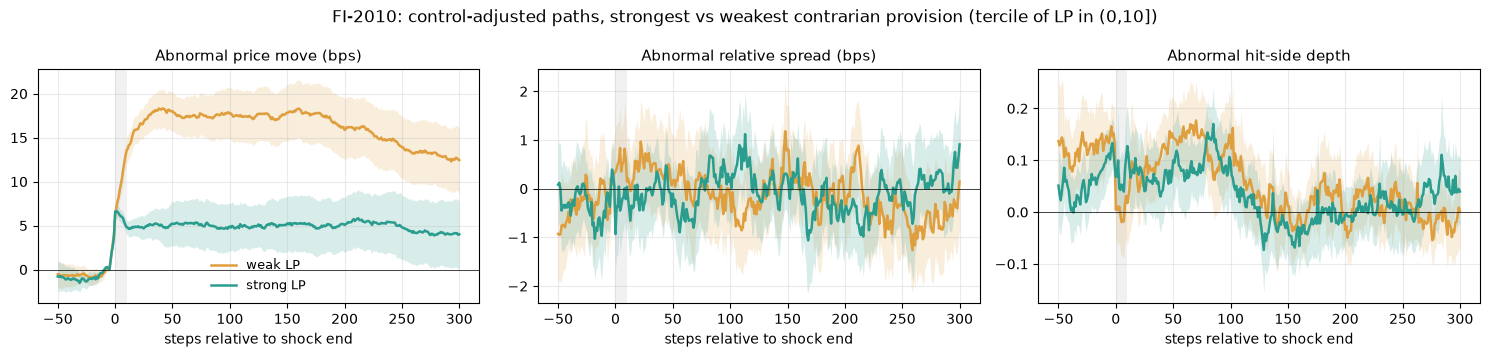

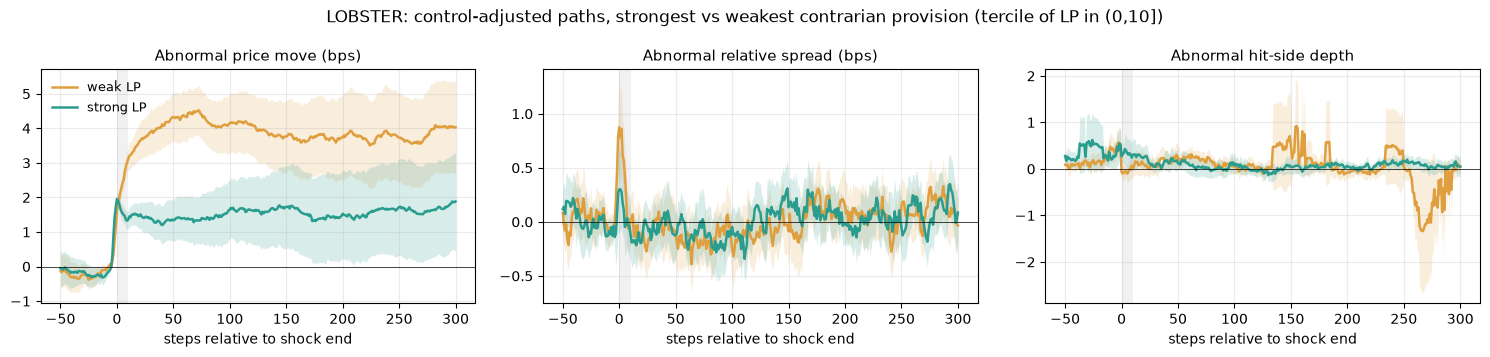

In [8]:
for name, fe in (("FI-2010", "seg"), ("LOBSTER", "stock")):
    df, res, e = out[name]
    lp = ("lp_flow", "lp_refill", "lp_msg") if name == "LOBSTER" else ("lp_flow", "lp_refill")
    reg, _, _ = A.h3_regressions(e, df, res, fe=fe, cluster="cluster", lp_vars=lp)
    print(name); display(reg.round(4))
for name in out:
    df, res, e = out[name]
    A.plot_terciles(e, res, name, [("mid_bps", "Abnormal price move (bps)"),
                                   ("rel_spread_bps", "Abnormal relative spread (bps)"),
                                   ("dep_press", "Abnormal hit-side depth")]); plt.show()

*Reading the tercile plots:* the gap between strong-LP and weak-LP events opens mostly inside the grey
provision window. There it is partly mechanical, because contrarian order flow moves the price at the same time.
The test of H3 is what happens **after** K1, which is what `reversal_bps` measures.

## 6. H4: adverse selection (LOBSTER trades)

For each market order (same-timestamp executions merged), using M₀ = the mid just before the trade and Mₕ = the mid h seconds later:
* effective half-spread $d(P-M_0)/M_0$;
* price impact $d(M_h-M_0)/M_0$, the adverse-selection cost;
* realised half-spread $d(P-M_h)/M_0$, what the passive liquidity provider keeps.

"Shock trades" are trades in the shock's direction during [−W, K1]; they hit the providers who absorb the shock.
They are compared with trades far from any event, with stock fixed effects, a log-size control and clustered SEs.

In [9]:
df, res, e = out["LOBSTER"]
tr = A.tag_trades(trades, df, e, W=5)
display(A.h4_table(tr).round(4))
df, res, e = out["FI-2010"]
e = e.assign(severity_q=pd.qcut(e["shock_size"], 5, labels=[1, 2, 3, 4, 5]))
print("FI-2010 proxy: post-shock drift against providers by shock-severity quintile")
display(e.groupby("severity_q", observed=True)[["impact_bps", "post_drift_abn_bps", "reversal_bps"]].mean().round(3))

,horizon_s,measure,normal_mean,shock_minus_normal,se,t,p,n_shock,n_normal,sig
0,1,impact,1.0881,0.9702,0.1599,6.0671,0.0000,2801,22752,***
1,1,realized,0.1821,-0.8473,0.1267,-6.6863,0.0000,2801,22752,***
2,5,impact,1.2379,1.2413,0.2174,5.7104,0.0000,2801,22752,***
3,5,realized,0.0324,-1.1184,0.1859,-6.0166,0.0000,2801,22752,***
4,30,impact,1.3791,1.1596,0.3636,3.1889,0.0014,2801,22752,***
5,30,realized,-0.1089,-1.0367,0.3522,-2.9437,0.0032,2801,22752,***
6,60,impact,1.5069,0.9327,0.3864,2.4139,0.0158,2801,22752,**
7,60,realized,-0.2367,-0.8098,0.3647,-2.2204,0.0264,2801,22752,**
8,0,effective half-spread,1.2702,0.1229,0.0603,2.0370,0.0416,2801,22752,**


FI-2010 proxy: post-shock drift against providers by shock-severity quintile


,impact_bps,post_drift_abn_bps,reversal_bps
severity_q,,,
1,6.1860,7.2140,-1.9930
2,5.3680,2.8360,-0.4280
3,5.0740,4.2280,-1.6120
4,5.3090,6.6750,-2.6350
5,8.4590,4.0060,0.4120


## 7. Shock types: where do prices revert, and where does provision matter?

Shocks are split by ex-ante characteristics:
* **severity tercile** (size of the flow shock), in both datasets;
* **driver** (LOBSTER only): *trade-driven* shocks, where most of the flow is aggressive market orders, vs
  *quote-driven* shocks, where most of it is cancellations and new quotes.

`drift_abn_bps` is the control-adjusted price drift over (0, 100]. The H3 columns re-estimate the recovery regression within each group.

In [10]:
display(pd.read_csv(TABLES / "10_shock_types.csv").round(3))

,dataset,split,group,events,impact_bps,drift_abn_bps,drift_t,reversal_bps,reversal_t,H2_refill_t,H3_refill_beta,H3_refill_t,H3_flow_beta,H3_flow_t
0,FI-2010,severity,medium,423,5.1800,4.7550,3.1050,-1.8030,-1.1830,0.5440,1.7270,1.2710,0.9820,0.7790
1,FI-2010,severity,mild,423,5.9150,5.4680,3.9000,-2.2940,-1.7850,-0.5420,1.8890,1.5820,2.7650,2.6410
2,FI-2010,severity,severe,423,7.1450,4.7550,3.9260,-1.1490,-0.8970,1.6920,0.3060,0.4120,-0.2300,-0.0940
3,LOBSTER,severity,medium,219,2.1190,1.2970,3.6440,-1.1750,-3.3210,-2.3630,-0.6240,-3.1790,0.6180,3.3060
4,LOBSTER,severity,mild,219,2.0890,1.3250,4.2870,-1.1940,-4.0090,-2.7460,0.6060,3.5490,-0.2110,-1.0360
5,LOBSTER,severity,severe,219,1.4760,1.1620,2.4070,-0.2450,-0.6220,1.1630,-0.8250,-2.4390,-0.1180,-0.3200
6,LOBSTER,driver,quote-driven,328,1.8420,0.3740,1.2700,-0.2240,-0.7730,1.2010,-0.6600,-2.0170,-0.3570,-1.2600
7,LOBSTER,driver,trade-driven,329,1.9470,2.1460,5.6690,-1.5170,-4.3510,-0.5090,-0.3400,-1.9000,0.1040,0.3200


## 8. Direct tests of dealer theory (LOBSTER)

A limit order book has no designated dealer, so we treat all passive liquidity providers together as "the dealer".
Every market order trades against them, so their inventory change is the mirror image of market-order flow.

| Test | Theory | Prediction |
|---|---|---|
| D1 inventory mean reversion | Amihud–Mendelson, Ho–Stoll | future provider flow opposite to inventory (β < 0) |
| D2 price reversal from inventory | same | holding the past return fixed, future return rises with inventory (β > 0); pure information → β = 0 |
| D3 spread vs inventory | Amihud–Mendelson | spread wider when inventory is far from target (β > 0) |
| D4 competition | Ho–Stoll | more competing quotes at the best price → narrower spread (β < 0) |
| D5 spread decomposition | Huang & Stoll (1997) | shares: order processing / inventory / adverse selection; normal vs shock |
| D6 who supplies liquidity | Biais–Declerck–Moinas | passive executions by age of the resting order: young (<1 s, fast re-quoting) vs older |

Inventory is measured over a rolling window of w seconds (60, 300 or 900), standardised per stock. Tests use a
1-second panel with non-overlapping samples. Every regression has stock fixed effects and SEs clustered by
stock × 30 minutes.

In [11]:
from mm import dealer as D
display(pd.read_csv(TABLES / "11_dealer_inventory_D1_D3.csv").round(4))
display(pd.read_csv(TABLES / "12_dealer_competition_D4.csv").round(4))
display(pd.read_csv(TABLES / "12b_orders_at_best_by_stock.csv").round(2))

,test,window_s,horizon_s,beta,se,t,p,n,prediction,sig
0,D1 future LP flow on inventory,60,10,0.1041,0.0290,3.5881,0.0003,10765,< 0 (unwind),***
1,D2 future return on inventory,60,10,-0.1351,0.0314,-4.2985,0.0000,10765,> 0 (reversal),***
2,D1 future LP flow on inventory,60,60,0.0263,0.0240,1.0962,0.2730,1790,< 0 (unwind),NaN
3,D2 future return on inventory,60,60,-0.4148,0.1728,-2.4003,0.0164,1790,> 0 (reversal),**
4,D1 future LP flow on inventory,60,300,0.0255,0.0215,1.1848,0.2361,350,< 0 (unwind),NaN
5,D2 future return on inventory,60,300,-0.6756,1.0297,-0.6561,0.5118,350,> 0 (reversal),NaN
6,D3 spread on |inventory|,60,0,-0.0697,0.0251,-2.7727,0.0056,10770,> 0,***
7,D1 future LP flow on inventory,300,10,0.0569,0.0218,2.6088,0.0091,10645,< 0 (unwind),***
8,D2 future return on inventory,300,10,-0.0148,0.0261,-0.5667,0.5709,10645,> 0 (reversal),NaN
9,D1 future LP flow on inventory,300,60,0.0224,0.0203,1.1055,0.2690,1770,< 0 (unwind),NaN


,test,spec,beta,se,t,p,n,prediction,sig
0,D4 spread on log(# orders at best),no depth control,0.4347,0.0806,5.3931,0.0000,10785,< 0,***
1,D4 spread on log(# orders at best),controlling for best-level depth,0.4652,0.0839,5.5468,0.0000,10785,< 0,***
2,D4 spread on log(# orders at best),AAPL only,0.2036,0.0555,3.6669,0.0002,2157,< 0,***
3,D4 spread on log(# orders at best),AMZN only,0.5758,0.1448,3.9772,0.0001,2157,< 0,***
4,D4 spread on log(# orders at best),GOOG only,0.9348,0.1001,9.3361,0.0000,2157,< 0,***
5,D4 spread on log(# orders at best),INTC only,-0.0294,0.0510,-0.5771,0.5639,2157,< 0,NaN
6,D4 spread on log(# orders at best),MSFT only,0.0474,0.0305,1.5545,0.1201,2157,< 0,NaN


,stock,n_bid_best,n_ask_best,spread_bps,depth1
0,AAPL,4.6700,4.5500,2.5900,304.5400
1,AMZN,5.8200,6.3200,5.6000,356.7100
2,GOOG,2.8400,2.7700,4.5900,307.2900
3,INTC,46.9700,31.7900,3.7300,"27,260.0100"
4,MSFT,45.1500,29.9000,3.3000,"22,425.6800"


**Price response after a market order** (the impulse response). Inventory models predict that part of the
impact reverts; adverse selection predicts that it does not. The error bars in the figure treat trades as
independent; table 14b gives the clustered test.

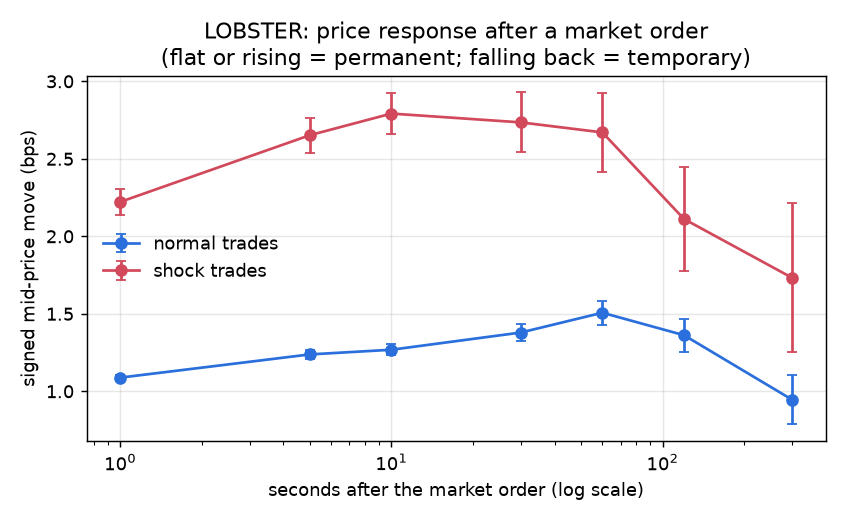

,period,from_s,to_s,change_bps,se,t,p,share_of_impact_reversed,n
0,normal,10,120,0.0938,0.1188,0.7895,0.4330,-0.0740,22752
1,normal,10,300,-0.3214,0.1910,-1.6833,0.0976,0.2535,22752
2,normal,60,300,-0.5603,0.1869,-2.9979,0.0040,0.3718,22752
3,shock,10,120,-0.6803,0.4779,-1.4236,0.1598,0.2437,2801
4,shock,10,300,-1.0589,0.5041,-2.1004,0.0400,0.3793,2801
5,shock,60,300,-0.9374,0.5200,-1.8026,0.0766,0.3510,2801


In [12]:
display(Image(filename=str(FIGS / "price_response_LOBSTER.png")))
display(pd.read_csv(TABLES / "14b_price_reversal_test.csv").round(4))

**Huang–Stoll (1997) decomposition.** Uses
$\Delta M_t = (\alpha+\beta)\tfrac{S_{t-1}}{2}Q_{t-1} - \alpha(1-2\pi)\tfrac{S_{t-2}}{2}Q_{t-2} + e_t$, where:
* α is the adverse-selection share and β the inventory share of the spread;
* 1 − α − β is the order-processing share;
* π is the probability that the next trade has the opposite sign.

The model was designed for dealer markets with mostly one-tick spreads. Negative α estimates (INTC, MSFT) show
that it fits modern limit order books poorly, so compare *normal vs shock* within a stock rather than reading the levels.

In [13]:
display(pd.read_csv(TABLES / "13_huang_stoll_D5.csv").round(4))

,stock,period,n,pi_reversal,adverse_selection,se_as,inventory,se_inv,order_processing
0,AAPL,all,19445,0.2034,0.0070,0.0094,0.1938,0.0083,0.7992
1,AAPL,normal,18452,0.2091,0.0048,0.0089,0.1947,0.0083,0.8005
2,AAPL,shock,993,0.0967,0.0736,0.0595,0.1801,0.0247,0.7463
3,AMZN,all,6332,0.1941,-0.0141,0.0209,0.2229,0.0197,0.7912
4,AMZN,normal,5962,0.2016,-0.0195,0.0202,0.2314,0.0175,0.7881
5,AMZN,shock,370,0.0730,0.0180,0.0540,0.1583,0.0399,0.8237
6,GOOG,all,5802,0.1868,-0.0382,0.0189,0.2324,0.0217,0.8058
7,GOOG,normal,5503,0.1914,-0.0397,0.0195,0.2341,0.0227,0.8055
8,GOOG,shock,299,0.1037,-0.0103,0.0362,0.2045,0.0207,0.8058
9,INTC,all,7439,0.1851,-0.0918,0.0159,0.1972,0.0228,0.8946


**Who supplies liquidity (D6).** Share of passive volume, and realised spread / price impact, by age of the executed resting order.

In [14]:
display(pd.read_csv(TABLES / "15_provider_volume_share_D6.csv").round(4))
display(pd.read_csv(TABLES / "15b_provider_performance_D6.csv").round(4))
display(pd.read_csv(TABLES / "15c_provider_regression_D6.csv").round(4))

,period,young (<1s),middle (1-60s),old (>60s)
0,normal,0.2217,0.5656,0.2127
1,shock,0.1574,0.6187,0.2239


,age_class,period,executions,realized_5s_bps,realized_60s_bps,impact_5s_bps,impact_60s_bps
0,young (<1s),normal,"9,196.0000",-0.2397,-0.8356,1.8529,2.4487
1,young (<1s),shock,"1,574.0000",-1.4657,-2.4955,3.2133,4.2431
2,middle (1-60s),normal,"19,431.0000",-0.8929,-1.5226,2.6173,3.2469
3,middle (1-60s),shock,"4,967.0000",-1.7911,-2.1992,3.5313,3.9394
4,old (>60s),normal,"5,395.0000",-0.4623,-1.3263,2.2338,3.0978
5,old (>60s),shock,"2,103.0000",-2.0460,-2.6416,3.8035,4.3991


,outcome,term,beta,se,t,p,sig,n
0,realized_5s_bps,shock,-1.1197,0.1106,-10.1205,0.0000,***,42666
1,realized_5s_bps,young,0.2599,0.0715,3.6334,0.0003,***,42666
2,realized_5s_bps,shock_x_young,0.0277,0.2494,0.1111,0.9115,NaN,42666
3,realized_60s_bps,shock,-0.8954,0.4121,-2.1730,0.0298,**,42666
4,realized_60s_bps,young,0.2064,0.1979,1.0430,0.2969,NaN,42666
5,realized_60s_bps,shock_x_young,-0.0798,0.8574,-0.0931,0.9259,NaN,42666


## 9. Robustness

The full grid is computed by `scripts/run_all.py` and saved as `results/tables/08_robustness.csv`. It covers:
* signal: OFI at level 1 or over 3 levels;
* W ∈ {3, 5, 10};
* tail q ∈ {0.5%, 1%, 2.5%, 5%};
* provision window K1 ∈ {5, 10, 20} and recovery horizon K2 ∈ {50, 100, 300}.

It also reports depth over 1 and 10 levels and hit-side quote improvements. Table 09 re-runs the earlier
notebook's definition (10-level depth imbalance, 5% tails) for comparison.

In [15]:
rob = pd.read_csv(TABLES / "08_robustness.csv"); display(rob.round(3))
display(pd.read_csv(TABLES / "09_depth_imbalance_definition.csv").round(3))

,dataset,signal,W,q,K1,K2,events,impact_bps,H1_spread,H1_spread_t,H1_depth,H1_depth_t,H1_depth10,H1_depth10_t,H2_improve,H2_improve_t,H2_flow,H2_flow_t,H2_refill,H2_refill_t,drift_bps,drift_t,H3_beta,H3_t
0,FI-2010,ofi1n,3,0.0050,10,100,980,5.1280,-0.1200,-0.3870,-0.8380,-14.7790,-0.0200,-2.4440,-0.0140,-0.3660,-0.4840,-2.1180,0.0110,0.5480,5.2050,5.3850,-0.8670,-0.8120
1,FI-2010,ofi1n,3,0.0100,10,100,1540,4.7120,0.2950,1.3450,-0.6570,-17.5880,-0.0020,-0.2530,-0.0660,-1.9380,-0.5260,-3.3280,0.0210,1.2320,4.8100,5.6430,-0.1560,-0.1100
2,FI-2010,ofi1n,3,0.0250,10,100,2187,3.9200,0.3840,1.6020,-0.4350,-14.5450,0.0070,0.9750,-0.0020,-0.0660,-0.6560,-7.4150,-0.0040,-0.2150,4.5500,8.4640,1.9300,2.9240
3,FI-2010,ofi1n,3,0.0500,10,100,2163,3.1970,0.4600,2.6640,-0.3000,-7.7700,0.0000,0.0030,0.1650,3.0380,-0.4880,-7.9050,0.0230,0.8740,3.7140,7.7130,2.3930,6.8720
4,FI-2010,ofi1n,5,0.0050,10,100,777,6.5300,0.2270,0.5700,-0.6640,-11.1490,-0.0190,-1.3180,-0.0830,-2.1950,-0.5520,-2.2590,-0.0100,-0.4560,4.2900,4.0390,-1.7580,-1.0970
5,FI-2010,ofi1n,5,0.0100,10,100,1269,6.0800,0.3930,1.5040,-0.5640,-12.3160,0.0020,0.2550,-0.0710,-2.0610,-0.5550,-3.5620,0.0220,1.2340,4.9930,6.1060,0.5340,0.4250
6,FI-2010,ofi1n,5,0.0250,10,100,2069,5.4740,0.6210,2.8400,-0.3960,-15.1900,0.0120,1.5680,-0.0540,-1.4800,-0.6720,-9.1670,0.0090,0.4890,4.4050,7.3830,2.2290,2.8450
7,FI-2010,ofi1n,5,0.0500,10,100,2181,4.3540,0.6240,2.2640,-0.2990,-9.1520,0.0060,1.1570,0.0340,0.8420,-0.5530,-7.5700,0.0160,0.7830,4.3950,5.9640,1.2080,2.0880
8,FI-2010,ofi1n,10,0.0050,10,100,578,9.5060,-0.3240,-0.7900,-0.5140,-6.7520,0.0140,0.7540,-0.1480,-4.5300,-0.5480,-1.7140,-0.0160,-0.6020,5.8130,4.0740,-0.6700,-0.5080
9,FI-2010,ofi1n,10,0.0100,10,100,993,9.3250,0.7230,1.7450,-0.4400,-13.6090,0.0320,2.4260,-0.0940,-2.1900,-0.6990,-3.6220,-0.0110,-0.5480,5.0390,4.8030,-0.2130,-0.1410


,dataset,signal,W,q,K1,K2,events,impact_bps,H1_spread,H1_spread_t,H1_depth,H1_depth_t,H1_depth10,H1_depth10_t,H2_improve,H2_improve_t,H2_flow,H2_flow_t,H2_refill,H2_refill_t,drift_bps,drift_t,H3_beta,H3_t
0,FI-2010,imb10,1,0.0500,10,100,1796,-1.2030,0.2600,1.7440,-0.1840,-12.8660,-0.1020,-22.5190,0.0460,1.6470,-0.1980,-3.2900,-0.0520,-4.0490,2.8380,3.5260,2.1610,4.3180
1,LOBSTER,imb10,1,0.0500,10,100,709,-0.1380,-0.0410,-0.8840,-0.1650,-9.3520,-0.1290,-6.8390,0.2830,4.0880,1.0350,3.2470,0.0790,0.5210,0.0250,0.1020,0.0320,0.2000


## 10. Summary

See `REPORT.md` for the write-up and how the results relate to Amihud–Mendelson (1980), Ho–Stoll (1983),
Biais–Weill (2009) and Biais–Declerck–Moinas (2016).